<a href="https://colab.research.google.com/github/bimaadiwijaya8/-ML_05_Bima-Adiwijaya/blob/main/JS11/JS11-Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normalisasi piksel ke [0.0, 1.0]
train_images = train_images.astype("float32") / 255.0
test_images = test_images.astype("float32") / 255.0

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("Train shape:", train_images.shape, "Test shape:", test_images.shape)

Train shape: (50000, 32, 32, 3) Test shape: (10000, 32, 32, 3)


In [2]:
tf.keras.utils.set_random_seed(42)

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(height_factor=0.08, width_factor=0.08),
    layers.RandomZoom(height_factor=0.08, width_factor=0.08),
], name="data_augmentation")

inputs = layers.Input(shape=(32, 32, 3))
x = data_augmentation(inputs)

# Blok 1
x = layers.Conv2D(32, (3, 3), padding="same", use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.Conv2D(32, (3, 3), padding="same", use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Dropout(0.2)(x)

# Blok 2
x = layers.Conv2D(64, (3, 3), padding="same", use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.Conv2D(64, (3, 3), padding="same", use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Dropout(0.25)(x)

# Blok 3
x = layers.Conv2D(128, (3, 3), padding="same", use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.Conv2D(128, (3, 3), padding="same", use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Dropout(0.3)(x)

# Classifier head
x = layers.Flatten()(x)
x = layers.Dense(128, use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(10)(x)

cifar_model = models.Model(inputs=inputs, outputs=outputs, name="CIFAR10_CNN_Improved")
cifar_model.summary()

Model: "CIFAR10_CNN_Improved"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 552,298 (2.11 MB)

 Trainable params: 551,146 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

Epoch 1/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 275s 348ms/step - accuracy: 0.5247 - loss: 1.3202 - val_accuracy: 0.4776 - val_loss: 1.6735 - learning_rate: 0.0010
Epoch 2/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 322s 348ms/step - accuracy: 0.6302 - loss: 1.0492 - val_accuracy: 0.6540 - val_loss: 0.9848 - learning_rate: 0.0010
Epoch 3/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 288s 368ms/step - accuracy: 0.6794 - loss: 0.9153 - val_accuracy: 0.7023 - val_loss: 0.8369 - learning_rate: 0.0010
Epoch 4/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 284s 363ms/step - accuracy: 0.7063 - loss: 0.8425 - val_accuracy: 0.6827 - val_loss: 0.9280 - learning_rate: 0.0010
Epoch 5/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 310s 347ms/step - accuracy: 0.7296 - loss: 0.7789 - val_accuracy: 0.7447 - val_loss: 0.7482 - learning_rate: 0.0010
Epoch 6/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 331s 359ms/step - accuracy: 0.7454 - loss: 0.7367 - val_accuracy: 0.7732 - val_loss: 0.6452 - learning_rate: 0.0010
Epoch 7/30
782/782 ━━━━━━━━━━━━━━━━━━━━ 313s 348ms/step - accura

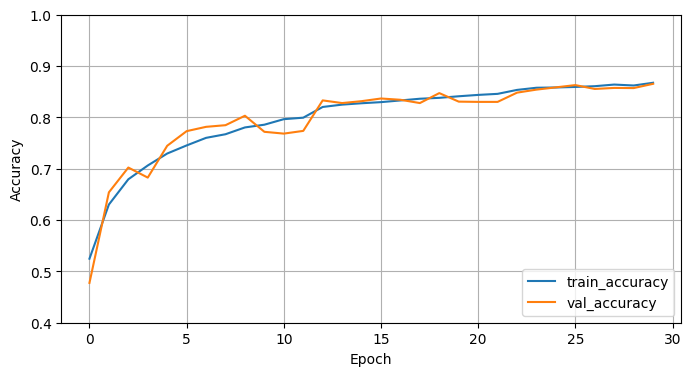

313/313 - 12s - 39ms/step - accuracy: 0.8654 - loss: 0.4134
Akurasi Testing CIFAR-10: 0.8654 (86.54%)


In [5]:
cifar_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"],
)

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_accuracy",
        factor=0.5,
        patience=3,
        min_lr=1e-5,
        verbose=1,
    )
]

history_cifar = cifar_model.fit(
    train_images,
    train_labels,
    epochs=30,
    batch_size=64,
    validation_data=(test_images, test_labels),
    callbacks=callbacks,
)

# Plot akurasi
plt.figure(figsize=(8, 4))
plt.plot(history_cifar.history["accuracy"], label="train_accuracy")
plt.plot(history_cifar.history["val_accuracy"], label="val_accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.ylim([0.4, 1.0])
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

test_loss, test_acc = cifar_model.evaluate(test_images, test_labels, verbose=2)
print(f"Akurasi Testing CIFAR-10: {test_acc:.4f} ({test_acc * 100:.2f}%)")

In [6]:
(mnist_train_x, mnist_train_y), (mnist_test_x, mnist_test_y) = datasets.mnist.load_data()

# Reshape menjadi (N, 28, 28, 1) dan normalisasi ke [0.0, 1.0]
mnist_train_x = (mnist_train_x.astype("float32") / 255.0)[..., tf.newaxis]
mnist_test_x = (mnist_test_x.astype("float32") / 255.0)[..., tf.newaxis]

print("MNIST Train shape:", mnist_train_x.shape, "Test shape:", mnist_test_x.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MNIST Train shape: (60000, 28, 28, 1) Test shape: (10000, 28, 28, 1)


Model: "MNIST_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 28s 58ms/step - accuracy: 0.9249 - loss: 0.2510 - val_accuracy: 0.9730 - val_loss: 0.0817
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 42s 60ms/step - accuracy: 0.9791 - loss: 0.0678 - val_accuracy: 0.9855 - val_loss: 0.0456
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 40s 57ms/step - accuracy: 0.9846 - loss: 0.0497 - val_accuracy: 0.9850 - val_loss: 0.0433
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 26s 56ms/step - accuracy: 0.9871 - loss: 0.0396 - val_accuracy: 0.9893 - val_loss: 0.0312
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 27s 58ms/step - accuracy: 0.9900 - loss: 0.0323 - val_accuracy: 0.9890 - val_loss: 0.0328
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 26s 56ms/step - accuracy: 0.9911 - loss: 0.0285 - val_accuracy: 0.9901 - val_loss: 0.0262
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 26s 56ms/step - accuracy: 0.9919 - loss: 0.0250 - val_accuracy: 0.9899 - val_loss: 0.0287
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 26s 56ms/step - accuracy: 0.9927 - loss: 0.0215 - 

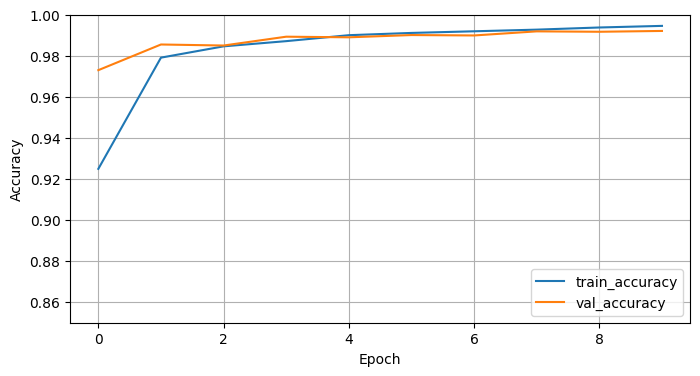

313/313 - 2s - 5ms/step - accuracy: 0.9921 - loss: 0.0253
Akurasi Testing MNIST: 0.9921 (99.21%)


In [7]:
tf.keras.utils.set_random_seed(42)

mnist_model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dropout(0.25),
    layers.Dense(64, activation="relu"),
    layers.Dense(10),
], name="MNIST_CNN")

mnist_model.summary()

mnist_model.compile(
    optimizer="adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"],
)

history_mnist = mnist_model.fit(
    mnist_train_x,
    mnist_train_y,
    epochs=10,
    batch_size=128,
    validation_data=(mnist_test_x, mnist_test_y),
)

plt.figure(figsize=(8, 4))
plt.plot(history_mnist.history["accuracy"], label="train_accuracy")
plt.plot(history_mnist.history["val_accuracy"], label="val_accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.ylim([0.85, 1.0])
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

mnist_test_loss, mnist_test_acc = mnist_model.evaluate(mnist_test_x, mnist_test_y, verbose=2)
print(f"Akurasi Testing MNIST: {mnist_test_acc:.4f} ({mnist_test_acc * 100:.2f}%)")